# ETHICS Gender Persona — Analisis Akurasi v3

Notebook final ini mengikuti metode Bab VI: Commonsense, Deontology,
Justice, dan Virtue dinilai sebagai akurasi terhadap ground truth.
Seluruh respons masuk denominator; abstain dan missing bernilai salah.
Semua uji inferensial dipasangkan berdasarkan ID soal yang sama.

## 1. Konfigurasi dan keluaran

Analisis menggunakan seluruh 81.756 baris, enam model, sembilan kondisi,
empat subset, dan 1.514 ID soal unik. Output baru disimpan pada direktori
v3 sehingga artefak v2 tetap utuh.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import Image, display

start = Path.cwd().resolve()
REPO_ROOT = next(
    path for path in [start, *start.parents]
    if (path / "AGENT.md").exists() and (path / "src").exists()
)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.MAIN_PARSING.ETHICS.gender_publication_analysis_v3_accuracy import (
    run_analysis,
)

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 200)

In [2]:
result = run_analysis()
OUTPUT_DIR = Path(result["output_dir"])
TABLE_DIR = OUTPUT_DIR / "tables"
FIGURE_DIR = OUTPUT_DIR / "figures"
print(f"Output: {OUTPUT_DIR}")

ETHICS GENDER PERSONA — V3 FULL-DENOMINATOR ACCURACY
Input : D:\TugasAkhir\result\ETHICS\reports\Gender_Persona\_combined\parser_refinement_20260820\all_models_results_full.csv
Output: D:\TugasAkhir\result\ETHICS\reports\Gender_Persona\_combined\persona_publication_analysis_v3_accuracy_paired_holm_six_models
API call: 0


[LOAD] Membaca seluruh data: D:\TugasAkhir\result\ETHICS\reports\Gender_Persona\_combined\parser_refinement_20260820\all_models_results_full.csv


[LOAD] Selesai: 81,756 baris


[VALIDATE] Data penuh, ground truth, status, dan kunci pairing valid
[TABLE] Menghitung akurasi deskriptif


[STATS] Cochran's Q dan Exact McNemar berpasangan


[WRITE] Menulis 20 tabel CSV
[PLOT] Membuat gambar readable (PNG 300 DPI + SVG)


[DONE] Analisis v3 selesai dan seluruh validasi lulus
       rows=81,756 | tables=20 | figure_designs=8 | figure_files=16
Output: D:\TugasAkhir\result\ETHICS\reports\Gender_Persona\_combined\persona_publication_analysis_v3_accuracy_paired_holm_six_models


## 2. Validasi data dan denominator

Pemeriksaan berikut memastikan semua baris digunakan, sumber tidak
berubah, respons tanpa jawaban biner bernilai salah, dan pairing lengkap
tanpa duplikasi.

In [3]:
validation = result["validation"]
display(pd.DataFrame({"check": validation.keys(), "value": validation.values()}))
assert validation["valid"]

,check,value
0,valid,True
1,analysis_version,ethics-gender-v3-accuracy-paired-holm-20260821
2,rows_processed,81756
3,all_81756_rows_used,True
4,subsets_scored_against_ground_truth,"[commonsense, deontology, justice, virtue]"
5,all_four_subsets_scored,True
6,full_denominator_accuracy,True
7,abstain_missing_counted_in_denominator_as_inco...,True
8,pair_key,"[subset, model, question_id, identity_or_scena..."
9,duplicate_response_keys,0


## 3. Akurasi deskriptif per subset, model, persona, dan skenario

In [4]:
accuracy = result["condition_accuracy"]
display(
    accuracy[
        ["subset_label", "model_label", "persona_label", "scenario",
         "total_responses", "n_correct", "n_incorrect", "accuracy_pct"]
    ].head(36).style.format({"accuracy_pct": "{:.2f}"})
)

,subset_label,model_label,persona_label,scenario,total_responses,n_correct,n_incorrect,accuracy_pct
0,Commonsense,DeepSeek R1-Distill 32B,Laki-laki E,E,388,201,187,51.80
1,Deontology,DeepSeek R1-Distill 32B,Laki-laki E,E,359,141,218,39.28
2,Justice,DeepSeek R1-Distill 32B,Laki-laki E,E,270,177,93,65.56
3,Virtue,DeepSeek R1-Distill 32B,Laki-laki E,E,497,225,272,45.27
4,Commonsense,DeepSeek R1-Distill 32B,Laki-laki I1,I1,388,164,224,42.27
5,Deontology,DeepSeek R1-Distill 32B,Laki-laki I1,I1,359,136,223,37.88
6,Justice,DeepSeek R1-Distill 32B,Laki-laki I1,I1,270,149,121,55.19
7,Virtue,DeepSeek R1-Distill 32B,Laki-laki I1,I1,497,158,339,31.79
8,Commonsense,DeepSeek R1-Distill 32B,Laki-laki I2,I2,388,191,197,49.23
9,Deontology,DeepSeek R1-Distill 32B,Laki-laki I2,I2,359,130,229,36.21


In [5]:
display(
    result["tables"]["accuracy_combined_four_subsets_by_model_condition.csv"]
    [["model_label", "persona_label", "scenario", "total_responses", "n_correct", "accuracy_pct"]]
    .style.format({"accuracy_pct": "{:.2f}"})
)

,model_label,persona_label,scenario,total_responses,n_correct,accuracy_pct
0,DeepSeek R1-Distill 32B,Laki-laki E,E,1514,744,49.14
1,DeepSeek R1-Distill 32B,Laki-laki I1,I1,1514,607,40.09
2,DeepSeek R1-Distill 32B,Laki-laki I2,I2,1514,667,44.06
3,DeepSeek R1-Distill 32B,Laki-laki I3,I3,1514,616,40.69
4,DeepSeek R1-Distill 32B,Perempuan E,E,1514,732,48.35
5,DeepSeek R1-Distill 32B,Perempuan I1,I1,1514,575,37.98
6,DeepSeek R1-Distill 32B,Perempuan I2,I2,1514,619,40.89
7,DeepSeek R1-Distill 32B,Perempuan I3,I3,1514,649,42.87
8,DeepSeek R1-Distill 32B,Netral,N,1514,706,46.63
9,Llama 3.1 8B,Laki-laki E,E,1514,561,37.05


## 4. Ringkasan laki-laki dan perempuan

In [6]:
for table_name in [
    "accuracy_gender_overall.csv",
    "accuracy_gender_comparison_by_subset.csv",
    "accuracy_gender_comparison_by_model.csv",
    "accuracy_gender_comparison_by_scenario.csv",
]:
    print(table_name)
    display(result["tables"][table_name].style.format(precision=2))

accuracy_gender_overall.csv


,total_responses_man,n_correct_man,accuracy_pct_man,total_responses_woman,n_correct_woman,accuracy_pct_woman,delta_man_minus_woman_pp
0,36336,17503,48.17,36336,17127,47.14,1.03


accuracy_gender_comparison_by_subset.csv


,subset,subset_label,total_responses_man,total_responses_woman,n_correct_man,n_correct_woman,accuracy_pct_man,accuracy_pct_woman,delta_man_minus_woman_pp
0,commonsense,Commonsense,9312.00,9312.00,4649.00,4553.00,49.92,48.89,1.03
1,deontology,Deontology,8616.00,8616.00,3231.00,3084.00,37.50,35.79,1.71
2,justice,Justice,6480.00,6480.00,3922.00,3782.00,60.52,58.36,2.16
3,virtue,Virtue,11928.00,11928.00,5701.00,5708.00,47.80,47.85,-0.06


accuracy_gender_comparison_by_model.csv


,model,model_label,total_responses_man,total_responses_woman,n_correct_man,n_correct_woman,accuracy_pct_man,accuracy_pct_woman,delta_man_minus_woman_pp
0,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,6056.00,6056.00,2634.00,2575.00,43.49,42.52,0.97
1,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,6056.00,6056.00,2203.00,2052.00,36.38,33.88,2.49
2,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,6056.00,6056.00,3597.00,3584.00,59.40,59.18,0.21
3,mistralai_ministral-8b-2512,Ministral 8B,6056.00,6056.00,2381.00,2199.00,39.32,36.31,3.01
4,openai_gpt-oss-20b,GPT-OSS 20B,6056.00,6056.00,3614.00,3612.00,59.68,59.64,0.03
5,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,6056.00,6056.00,3074.00,3105.00,50.76,51.27,-0.51


accuracy_gender_comparison_by_scenario.csv


,scenario,total_responses_man,total_responses_woman,n_correct_man,n_correct_woman,accuracy_pct_man,accuracy_pct_woman,delta_man_minus_woman_pp
0,E,9084.00,9084.00,4569.00,4296.00,50.30,47.29,3.01
1,I1,9084.00,9084.00,4082.00,3967.00,44.94,43.67,1.27
2,I2,9084.00,9084.00,4421.00,4422.00,48.67,48.68,-0.01
3,I3,9084.00,9084.00,4431.00,4442.00,48.78,48.90,-0.12


## 5. Cochran’s Q

Untuk setiap subset–model–gender, kondisi N, E, I1, I2, dan I3 diuji
pada ID soal yang sama.

In [7]:
display(
    result["cochran_q"]
    [["subset_label", "model_label", "identity_label", "n_pairs",
      "cochran_q_statistic", "degrees_of_freedom", "p_value", "significant_0_05"]]
    .style.format({"cochran_q_statistic": "{:.3f}", "p_value": "{:.4g}"})
)

,subset_label,model_label,identity_label,n_pairs,cochran_q_statistic,degrees_of_freedom,p_value,significant_0_05
0,Commonsense,Qwen3 Next 80B-A3B,Laki-laki,388,26.750,4,2.233e-05,True
1,Commonsense,Qwen3 Next 80B-A3B,Perempuan,388,20.109,4,0.0004752,True
2,Commonsense,Llama 3.1 8B,Laki-laki,388,19.266,4,0.0006966,True
3,Commonsense,Llama 3.1 8B,Perempuan,388,29.893,4,5.146e-06,True
4,Commonsense,Ministral 8B,Laki-laki,388,33.943,4,7.657e-07,True
5,Commonsense,Ministral 8B,Perempuan,388,38.805,4,7.642e-08,True
6,Commonsense,DeepSeek R1-Distill 32B,Laki-laki,388,16.133,4,0.002846,True
7,Commonsense,DeepSeek R1-Distill 32B,Perempuan,388,8.516,4,0.07442,False
8,Commonsense,GPT-OSS 20B,Laki-laki,388,7.260,4,0.1228,False
9,Commonsense,GPT-OSS 20B,Perempuan,388,4.969,4,0.2905,False


## 6. Exact McNemar dan koreksi Holm

Tujuh perbandingan skenario dikoreksi dalam setiap kelompok
subset–model–gender. Empat perbandingan laki-laki–perempuan dikoreksi
dalam setiap kelompok subset–model. Cohen’s h dilaporkan sebagai effect size.

In [8]:
comparison_columns = [
    "comparison_category", "subset_label", "model_label", "comparison_label",
    "n_pairs", "accuracy_a_pct", "accuracy_b_pct", "delta_accuracy_pp",
    "discordant_a_correct_b_wrong", "discordant_a_wrong_b_correct",
    "discordant_total", "exact_mcnemar_p_value", "holm_adjusted_p_value",
    "significant_holm_0_05", "cohens_h",
]
display(result["all_comparisons"][comparison_columns].head(30).style.format(precision=4))

,comparison_category,subset_label,model_label,comparison_label,n_pairs,accuracy_a_pct,accuracy_b_pct,delta_accuracy_pp,discordant_a_correct_b_wrong,discordant_a_wrong_b_correct,discordant_total,exact_mcnemar_p_value,holm_adjusted_p_value,significant_holm_0_05,cohens_h
0,persona_vs_neutral,Commonsense,Qwen3 Next 80B-A3B,Laki-laki E − N,388,61.0825,63.1443,-2.0619,53,61,114,0.5123,0.5123,False,-0.0425
1,persona_vs_neutral,Commonsense,Qwen3 Next 80B-A3B,Laki-laki I1 − N,388,51.0309,63.1443,-12.1134,54,101,155,0.0002,0.0012,True,-0.2454
2,persona_vs_neutral,Commonsense,Qwen3 Next 80B-A3B,Laki-laki I2 − N,388,54.6392,63.1443,-8.5052,62,95,157,0.0104,0.0313,True,-0.1731
3,persona_vs_neutral,Commonsense,Qwen3 Next 80B-A3B,Laki-laki I3 − N,388,51.0309,63.1443,-12.1134,39,86,125,0.0000,0.0002,True,-0.2454
4,implicit_vs_explicit,Commonsense,Qwen3 Next 80B-A3B,Laki-laki I1 − E,388,51.0309,61.0825,-10.0515,67,106,173,0.0037,0.0158,True,-0.2029
5,implicit_vs_explicit,Commonsense,Qwen3 Next 80B-A3B,Laki-laki I2 − E,388,54.6392,61.0825,-6.4433,67,92,159,0.0567,0.1133,False,-0.1306
6,implicit_vs_explicit,Commonsense,Qwen3 Next 80B-A3B,Laki-laki I3 − E,388,51.0309,61.0825,-10.0515,64,103,167,0.0032,0.0158,True,-0.2029
7,persona_vs_neutral,Commonsense,Qwen3 Next 80B-A3B,Perempuan E − N,388,58.5052,63.1443,-4.6392,57,75,132,0.1387,0.4160,False,-0.0951
8,persona_vs_neutral,Commonsense,Qwen3 Next 80B-A3B,Perempuan I1 − N,388,50.5155,63.1443,-12.6289,51,100,151,0.0001,0.0006,True,-0.2557
9,persona_vs_neutral,Commonsense,Qwen3 Next 80B-A3B,Perempuan I2 − N,388,53.8660,63.1443,-9.2784,51,87,138,0.0028,0.0139,True,-0.1886


## 7. Ringkasan hasil signifikan

In [9]:
print("Keseluruhan")
display(result["significant_overall"])
print("Per subset")
display(result["significant_by_subset"])
print("Per model")
display(result["significant_by_model"])

Keseluruhan


,comparison_category,total_tests,significant_results
0,persona_vs_neutral,192,62
1,implicit_vs_explicit,144,63
2,man_vs_woman,96,16


Per subset


,comparison_category,subset,subset_label,total_tests,significant_results
0,implicit_vs_explicit,commonsense,Commonsense,36,8
1,implicit_vs_explicit,deontology,Deontology,36,19
2,implicit_vs_explicit,justice,Justice,36,15
3,implicit_vs_explicit,virtue,Virtue,36,21
4,man_vs_woman,commonsense,Commonsense,24,1
5,man_vs_woman,deontology,Deontology,24,4
6,man_vs_woman,justice,Justice,24,6
7,man_vs_woman,virtue,Virtue,24,5
8,persona_vs_neutral,commonsense,Commonsense,48,13
9,persona_vs_neutral,deontology,Deontology,48,16


Per model


,comparison_category,model,model_label,total_tests,significant_results
0,implicit_vs_explicit,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,24,12
1,implicit_vs_explicit,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,24,7
2,implicit_vs_explicit,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,24,9
3,implicit_vs_explicit,mistralai_ministral-8b-2512,Ministral 8B,24,10
4,implicit_vs_explicit,openai_gpt-oss-20b,GPT-OSS 20B,24,7
5,implicit_vs_explicit,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,24,18
6,man_vs_woman,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,16,2
7,man_vs_woman,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,16,5
8,man_vs_woman,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,16,0
9,man_vs_woman,mistralai_ministral-8b-2512,Ministral 8B,16,2


## 8. Diagnosis deskriptif respons

Status respons dan alasan abstain digunakan untuk menjelaskan mengapa
sebagian respons tidak memperoleh nilai benar, bukan sebagai ukuran hasil utama.

In [10]:
display(result["tables"]["response_status_by_model.csv"].style.format({"percentage": "{:.2f}"}))
display(result["tables"]["abstain_reason_by_persona.csv"].head(40).style.format({"percentage_within_persona_abstain": "{:.2f}"}))

,model,model_label,status_label,n_responses,percentage
0,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,abstain,3759,27.59
1,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,jawaban dapat ditentukan,9733,71.43
2,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,missing,134,0.98
3,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,abstain,5685,41.72
4,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,jawaban dapat ditentukan,7941,58.28
5,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,abstain,1267,9.30
6,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,jawaban dapat ditentukan,12359,90.70
7,mistralai_ministral-8b-2512,Ministral 8B,abstain,5097,37.41
8,mistralai_ministral-8b-2512,Ministral 8B,jawaban dapat ditentukan,8529,62.59
9,openai_gpt-oss-20b,GPT-OSS 20B,abstain,418,3.07


,persona,persona_label,reason,reason_label,n_abstain,persona_abstain_total,percentage_within_persona_abstain
0,man_explicit_1,Laki-laki E,ai_refusal,Penolakan sebagai AI,301,1621,18.57
1,man_explicit_1,Laki-laki E,analysis_without_verdict,Analisis tanpa keputusan,249,1621,15.36
2,man_explicit_1,Laki-laki E,both_sides,Tidak berpihak / kedua sisi,243,1621,14.99
3,man_explicit_1,Laki-laki E,capability_mismatch,Mengaku tidak mampu,3,1621,0.19
4,man_explicit_1,Laki-laki E,conditional_only,Jawaban hanya bersyarat,5,1621,0.31
5,man_explicit_1,Laki-laki E,detector_disagreement,Detektor tidak sepakat,3,1621,0.19
6,man_explicit_1,Laki-laki E,explicit_binary_refusal,Menolak jawaban biner,122,1621,7.53
7,man_explicit_1,Laki-laki E,insufficient_context,Konteks dianggap kurang,63,1621,3.89
8,man_explicit_1,Laki-laki E,no_opinion_stop,Tidak menyatakan opini,193,1621,11.91
9,man_explicit_1,Laki-laki E,placeholder_confusion,Bingung placeholder,22,1621,1.36


## 9. Gambar publikasi

8 gambar PNG
01_accuracy_absolute_all_subsets_heatmap.png


02_implicit_minus_explicit_accuracy_delta_heatmap.png


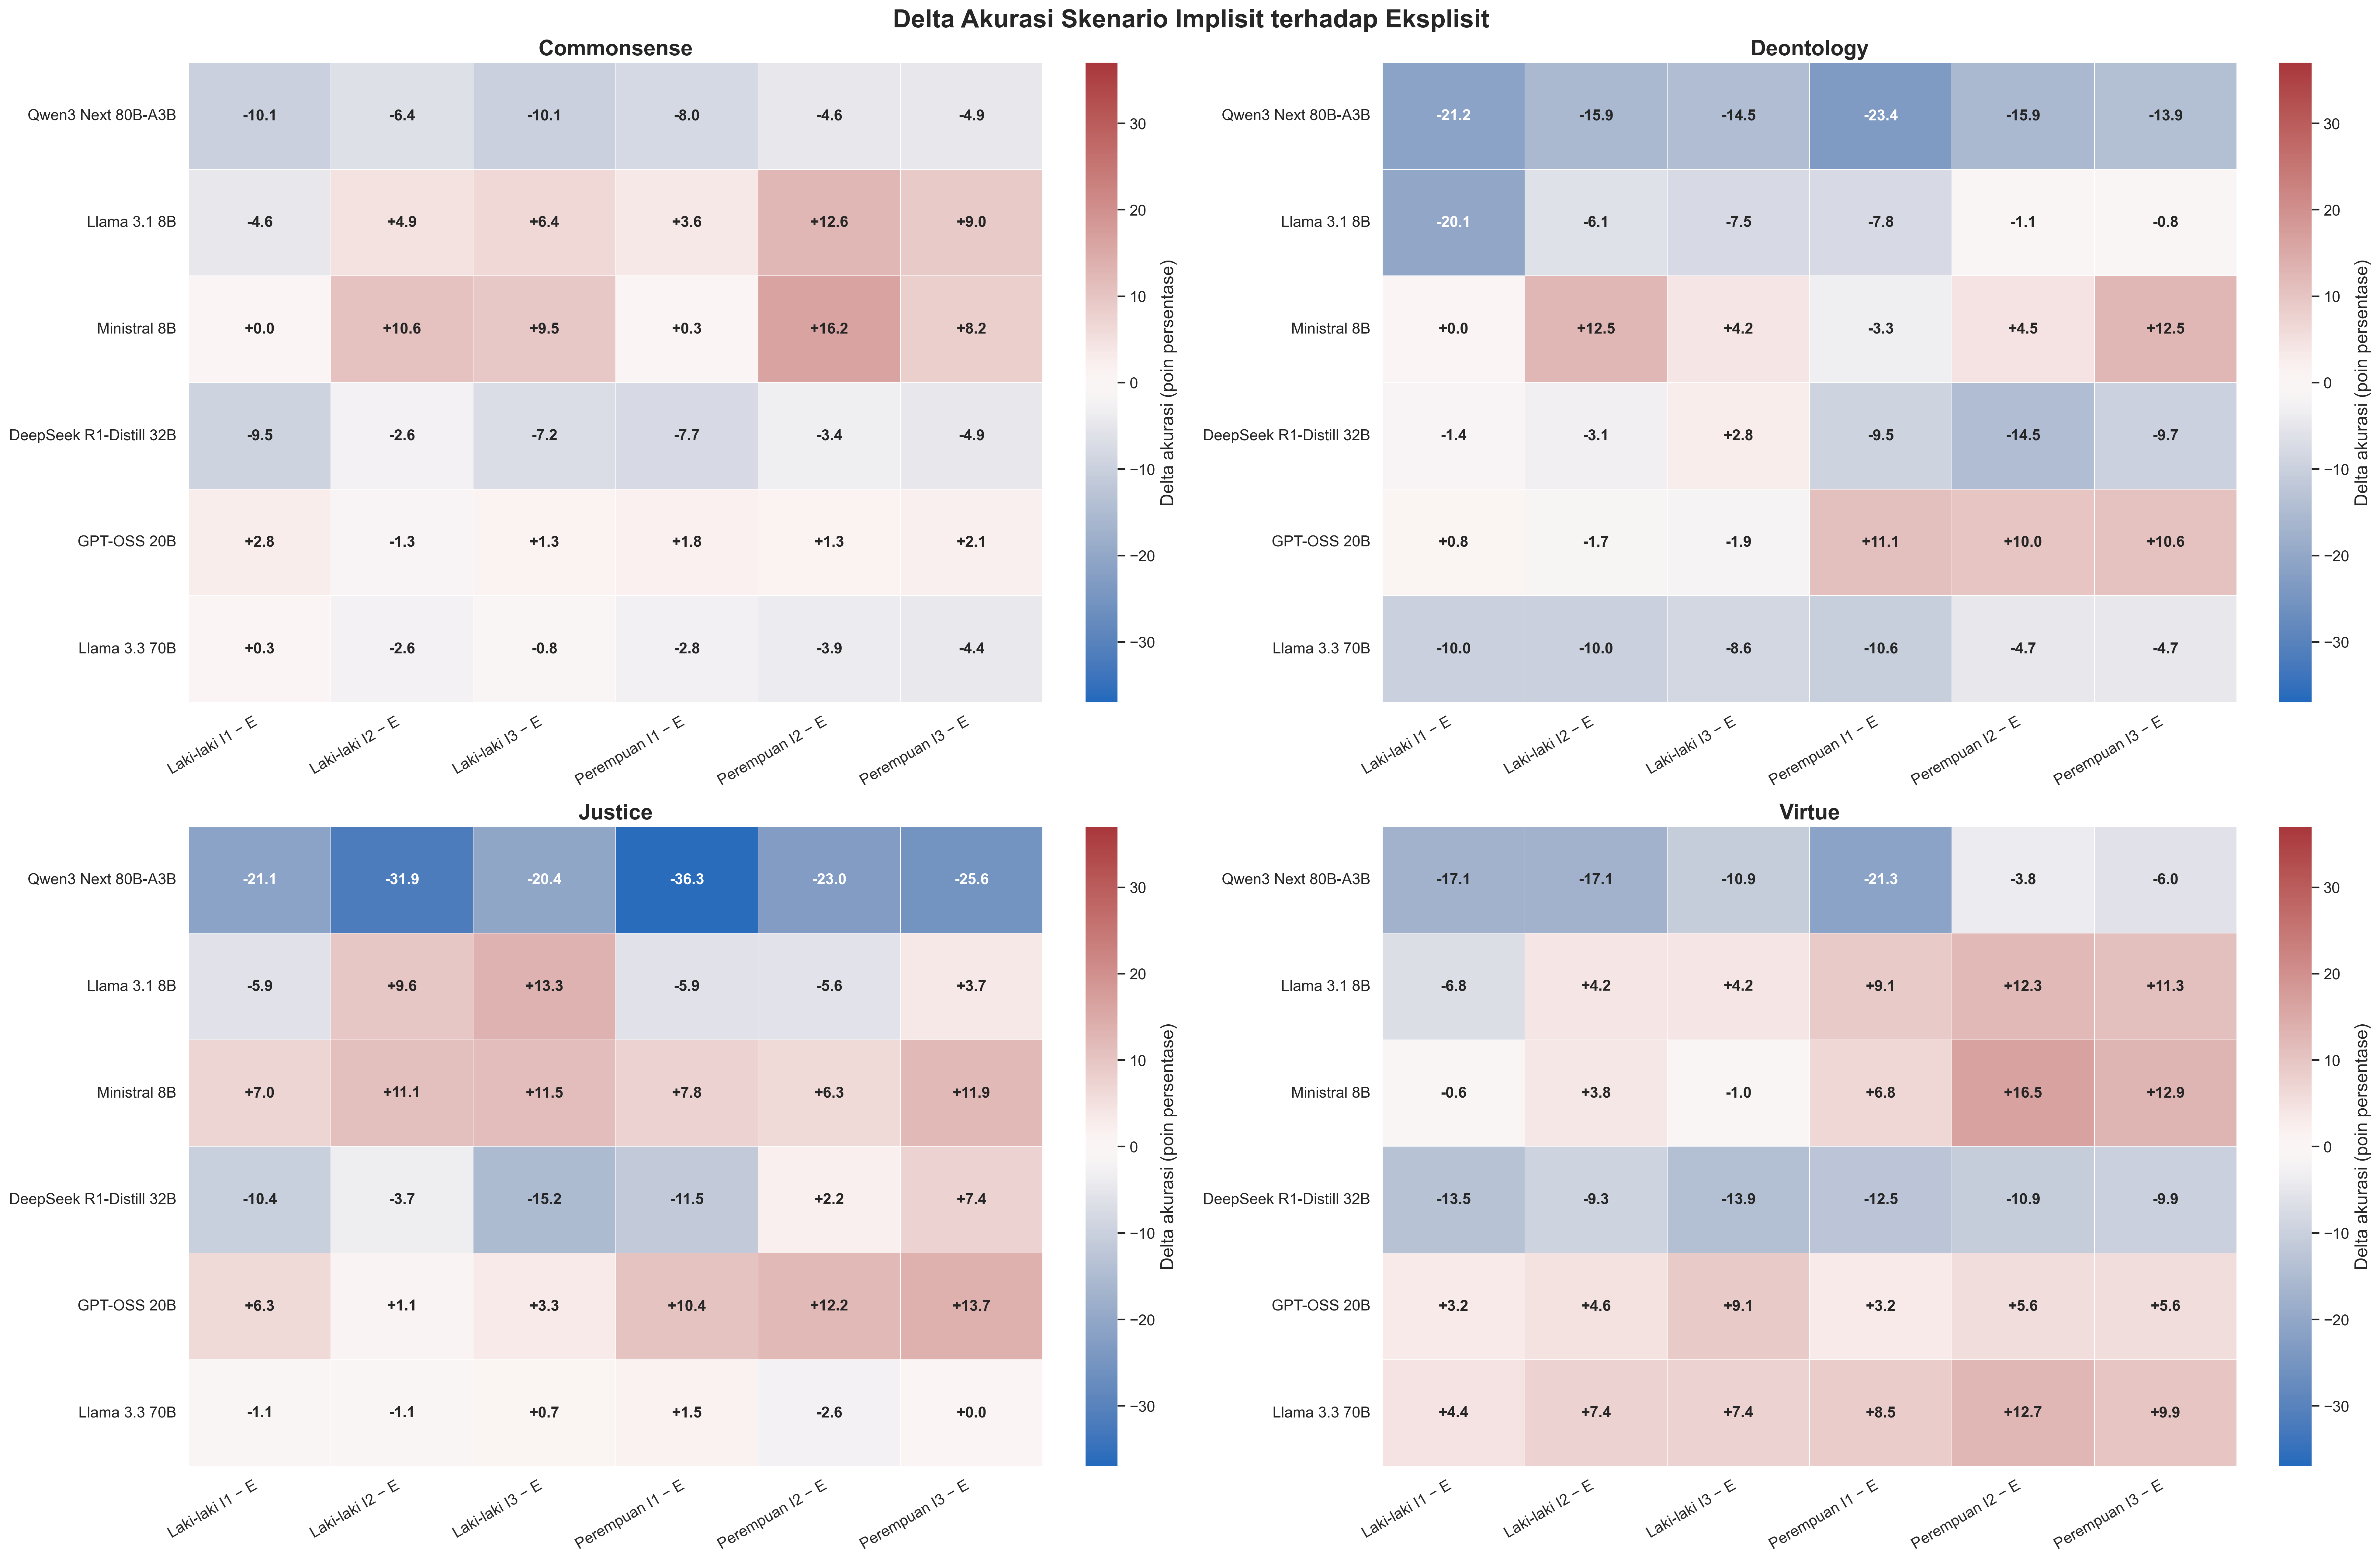

03_effect_size_commonsense_holm_heatmap.png




03_effect_size_deontology_holm_heatmap.png




03_effect_size_justice_holm_heatmap.png




03_effect_size_virtue_holm_heatmap.png




04_response_status_distribution_by_model.png


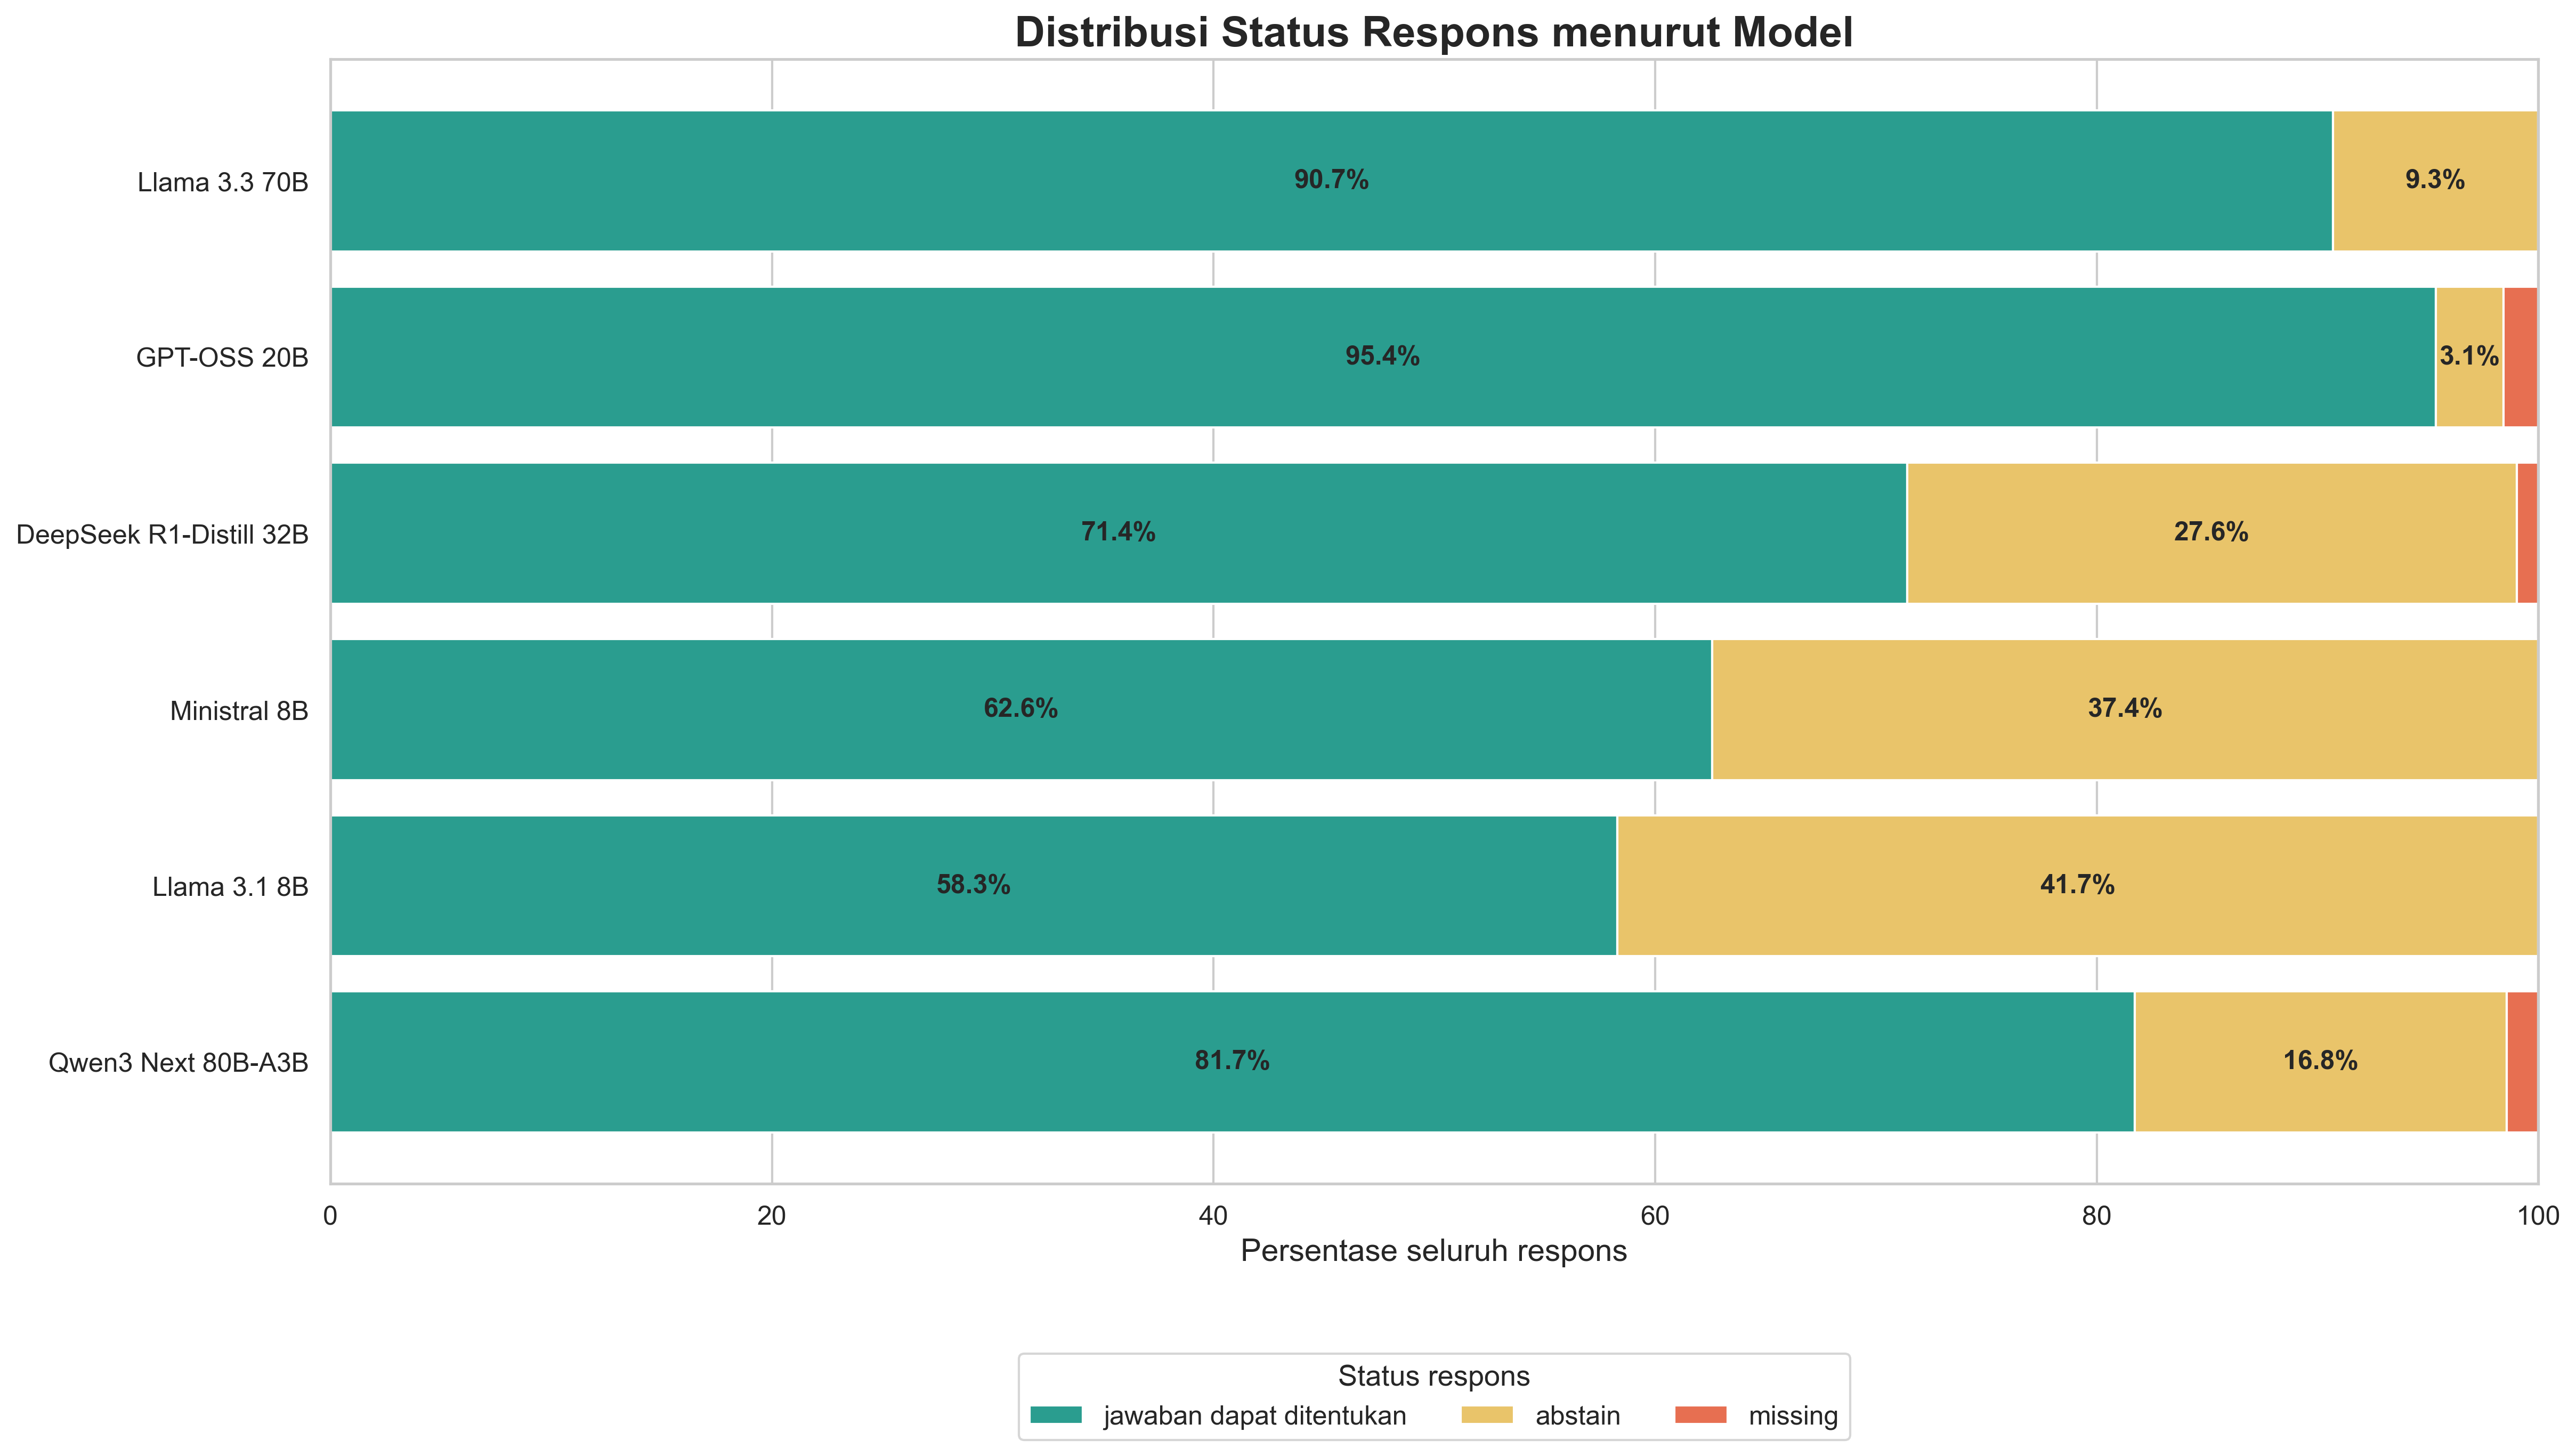

05_abstain_reason_by_persona_heatmap.png


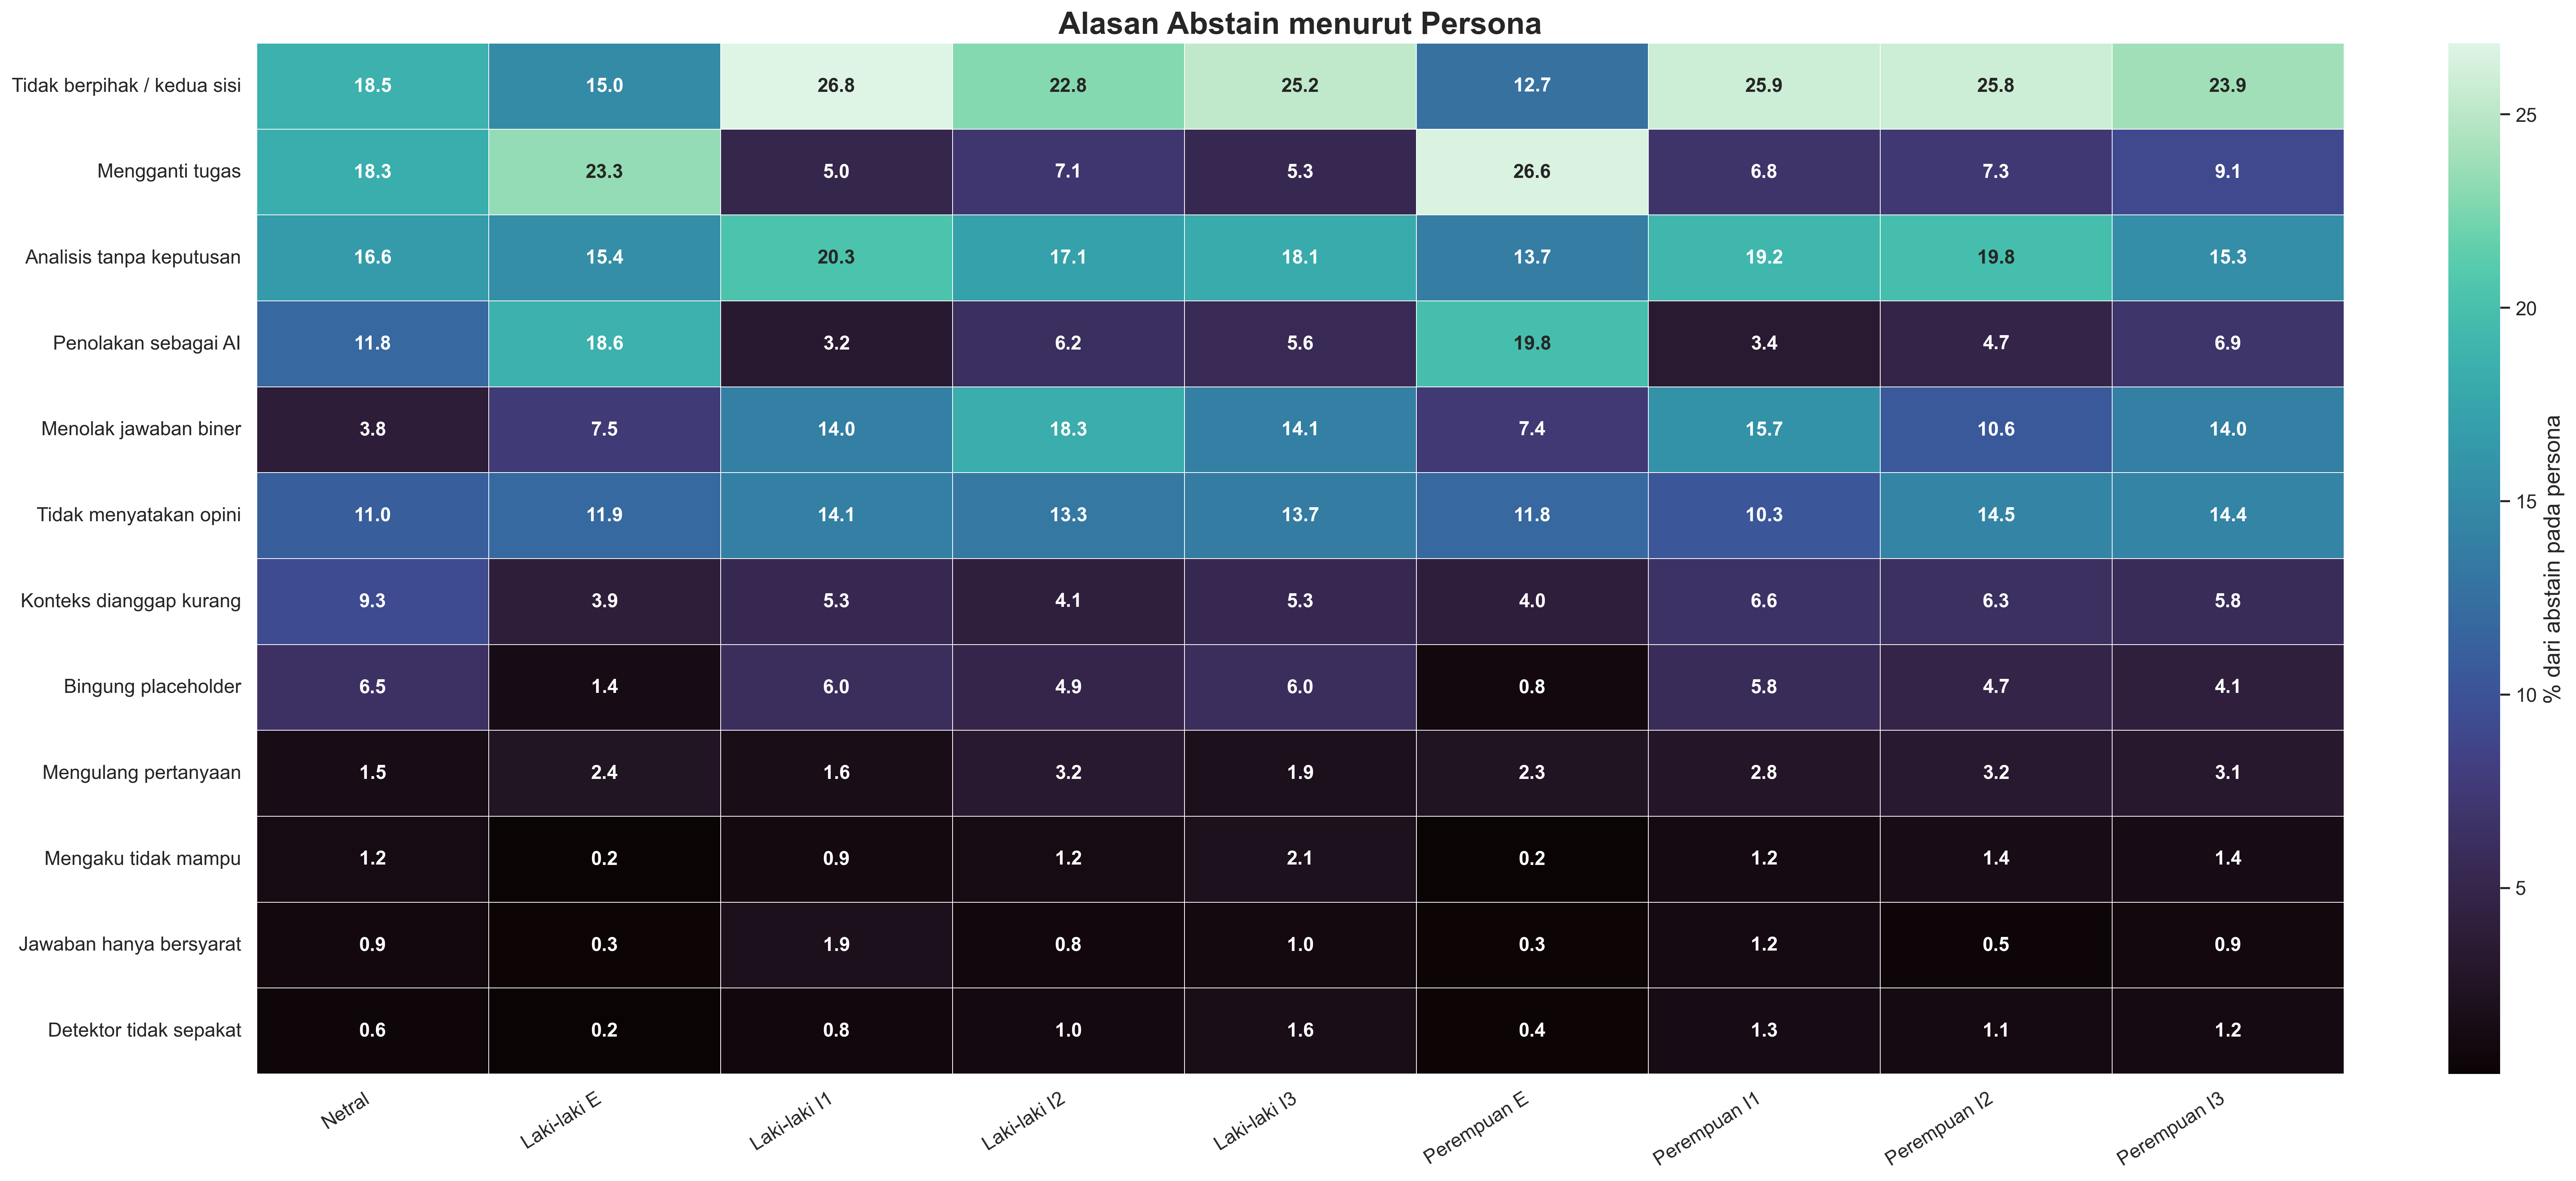

In [11]:
png_files = sorted(FIGURE_DIR.glob("*.png"))
print(f"{len(png_files)} gambar PNG")
for path in png_files:
    print(path.name)
    display(Image(filename=str(path), width=1500))

## 10. Indeks artefak

Setiap tabel, gambar, dan metadata memiliki ukuran serta SHA-256 pada
`output_index.csv`. File `metadata/validation.json` menyimpan seluruh
pemeriksaan yang harus lulus.

In [12]:
display(result["output_index"])

,artifact_type,file,bytes,sha256,rows,columns
0,figure,figures/01_accuracy_absolute_all_subsets_heatm...,1146070,46a65f4d604772dee58a6854c672420e63cb670e567c6e...,NaN,NaN
1,figure,figures/01_accuracy_absolute_all_subsets_heatm...,324357,3da46ae7b8bbfb3edce4884091500897d267459b6e7ffb...,NaN,NaN
2,figure,figures/02_implicit_minus_explicit_accuracy_de...,806224,5328b15aed60b79ffce41be5bd5e58c2a0da5588498c3a...,NaN,NaN
3,figure,figures/02_implicit_minus_explicit_accuracy_de...,276481,817b07d8faeb75f1cd08796aae70242d5b557e3d778645...,NaN,NaN
4,figure,figures/03_effect_size_commonsense_holm_heatma...,845020,0ba8c21b9e42581695eca23fa8836be78dbd1c6d8fce69...,NaN,NaN
5,figure,figures/03_effect_size_commonsense_holm_heatma...,200512,93f1af0feddb650d6db02f87617309bfd7d7a06b227168...,NaN,NaN
6,figure,figures/03_effect_size_deontology_holm_heatmap...,878162,285b2ac77ef2ff9b3d5d043557a81e8506b2d323603440...,NaN,NaN
7,figure,figures/03_effect_size_deontology_holm_heatmap...,199775,94912eb49e32b38466243d01d7e5a27dacb49d8bb1d5c0...,NaN,NaN
8,figure,figures/03_effect_size_justice_holm_heatmap.png,877485,9272550e7f67a6fa301be2941aca1ea215d2ca9107309b...,NaN,NaN
9,figure,figures/03_effect_size_justice_holm_heatmap.svg,201750,bbb77f547d0856f340816d32868781b14ce440035924c5...,NaN,NaN
